# 05. Final model: three-seed LSTM ensemble

The final model is the **average of three LSTMs** (64 hidden units, seeds 42, 43 and 44) with two heads: next-day log return
(for the close price) and next-day volatility. Averaging seeds removes most of the run-to-run variance from random
initialisation and batch order.

In notebook 04 the lowest validation loss belonged to a single 128-unit LSTM, but its margin over this ensemble was tiny
(0.8976 vs 0.9009) and it took about 20 minutes to train. The ensemble was chosen for stability and cost. The test results
below are for reporting and were not used to pick it.

This notebook retrains the three members (the ensemble was not saved in `04`), re-scores it, checks it against the
numbers from `04`, and saves it for the prediction script.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingRegressor

from formative_1 import stock_data as sd
from formative_1.lstm_model import DEVICE, TwoHeadLSTM, fit, predict
from formative_1.scoring import day_clustered_gain

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
print("device:", DEVICE)

device: cpu


## Data, split and scaling (same as notebooks 02 and 04)

In [2]:
clean = pl.read_parquet("../data/processed/clean.parquet")
X, y, day, ticker, close, y_vol = sd.make_windows(
    sd.add_features(clean), extras=("Ticker", "Close", "target_vol")
)
train, val, test = sd.split_masks(day)

mean, std = X[train].mean(axis=(0, 1)), X[train].std(axis=(0, 1))
y_std, vol_std = float(y[train].std()), float(y_vol[train].std())
Xs = torch.from_numpy((X - mean) / std)
Y = torch.from_numpy(np.column_stack([y / y_std, y_vol / vol_std]).astype(np.float32))

tickers = np.unique(ticker)
ticker_id = torch.from_numpy(np.searchsorted(tickers, ticker))
train_tickers = np.unique(ticker[train])
print(f"{len(y):,} samples; train {train.sum():,} / val {val.sum():,} / test {test.sum():,}; {len(tickers)} tickers ({len(train_tickers)} with training data)")

299,770 samples; train 204,210 / val 43,031 / test 52,529; 61 tickers (53 with training data)


## Reference forecasts

In [3]:
T, names = sd.window_summary(X)
col = {n: i for i, n in enumerate(names)}
ref_vol = T[:, col["hl_mean_5"]]
gb = HistGradientBoostingRegressor(
    max_depth=6, max_iter=200, learning_rate=0.05, min_samples_leaf=200, l2_regularization=1.0, random_state=SEED
).fit(T[train], y_vol[train] / vol_std)
gb_vol = gb.predict(T) * vol_std
zero_ret = np.zeros_like(y)
display(Markdown(f"Gradient boosting volatility MSE: val {np.mean((gb_vol[val] - y_vol[val]) ** 2):.3e}, test {np.mean((gb_vol[test] - y_vol[test]) ** 2):.3e}."))

Gradient boosting volatility MSE: val 2.940e-04, test 1.907e-04.

In [4]:
def evaluate(name, scaled_pred, rows):
    pr, pv = scaled_pred[:, 0] * y_std, scaled_pred[:, 1] * vol_std
    for split, mask in [("val", val), ("test", test)]:
        mse_r = float(np.mean((y[mask] - pr[mask]) ** 2))
        mse_v = float(np.mean((y_vol[mask] - pv[mask]) ** 2))
        ref_mse = float(np.mean((y_vol[mask] - ref_vol[mask]) ** 2))
        g_r, ci_r = day_clustered_gain(y, pr, zero_ret, day, mask)
        g_ref, ci_ref = day_clustered_gain(y_vol, pv, ref_vol, day, mask)
        g_gb, ci_gb = day_clustered_gain(y_vol, pv, gb_vol, day, mask)
        rows.append(
            {
                "model": name, "split": split,
                "val_loss": float(np.mean((scaled_pred[mask] - Y.numpy()[mask]) ** 2)),
                "ret_mse": mse_r,
                "ret_r2_vs_zero": 1 - mse_r / float(np.mean(y[mask] ** 2)),
                "ret_direction": float(np.mean(np.sign(y[mask]) == np.sign(pr[mask]))) if pr.any() else float("nan"),
                "ret_gain": g_r, "ret_ci95": ci_r,
                "vol_mse": mse_v,
                "vol_r2": 1 - mse_v / float(np.var(y_vol[mask])),
                "vol_r2_vs_ref": 1 - mse_v / ref_mse,
                "vol_gain_vs_ref": g_ref, "vol_ci_ref": ci_ref,
                "vol_gain_vs_gb": g_gb, "vol_ci_gb": ci_gb,
            }
        )


def train_variant(name, seed=SEED, hidden=64, use_ticker=False, verbose=False):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = TwoHeadLSTM(len(sd.FEATURES), hidden=hidden, n_tickers=len(tickers) if use_ticker else 0)
    t0 = time.time()
    tid = ticker_id if use_ticker else None
    model, history = fit(model, Xs, Y, train, val, ticker=tid, seed=seed, verbose=verbose)
    pred = predict(model, Xs, tid)
    print(f"{name}: {len(history)} epochs, best val loss {min(h['val'] for h in history):.4f}, {time.time() - t0:.0f}s")
    return model, history, pred


def train_member(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = TwoHeadLSTM(len(sd.FEATURES), hidden=64)
    t0 = time.time()
    model, history = fit(model, Xs, Y, train, val, seed=seed, verbose=False)
    print(f"seed {seed}: {len(history)} epochs, best val loss {min(h['val'] for h in history):.4f}, {time.time() - t0:.0f}s")
    return model, predict(model, Xs)

## Train the three members

In [5]:
members, member_preds = [], []
for seed in (42, 43, 44):
    m, p = train_member(seed)
    members.append(m)
    member_preds.append(p)
ens_pred = np.mean(member_preds, axis=0)

seed 42: 11 epochs, best val loss 0.9023, 484s


seed 43: 14 epochs, best val loss 0.8993, 560s


seed 44: 8 epochs, best val loss 0.9102, 306s


## Scores

The members and the ensemble are scored next to the baselines. The direction column is blank for constant predictions.

In [6]:
rows = []
evaluate("baseline: zero return + gradient boosting", np.column_stack([zero_ret / y_std, gb_vol / vol_std]), rows)
evaluate("baseline: zero return + 5-day mean range", np.column_stack([zero_ret / y_std, ref_vol / vol_std]), rows)
for seed, p in zip((42, 43, 44), member_preds):
    evaluate(f"LSTM 64 seed {seed}", p, rows)
evaluate("LSTM ensemble", ens_pred, rows)
results = pl.DataFrame(rows)
r4 = lambda *c: pl.col(*c).round(4)

display(Markdown("**Return head, test period** (gain over predicting zero, 95% CI by day)"))
display(results.filter(pl.col("split") == "test").select("model", r4("ret_r2_vs_zero"), r4("ret_direction"), pl.col("ret_gain").round(9), pl.col("ret_ci95").round(9)))
display(Markdown("**Volatility head, test period**"))
display(results.filter(pl.col("split") == "test").select("model", r4("vol_r2"), r4("vol_r2_vs_ref"), pl.col("vol_gain_vs_ref").round(9), pl.col("vol_ci_ref").round(9), pl.col("vol_gain_vs_gb").round(9), pl.col("vol_ci_gb").round(9)))

**Return head, test period** (gain over predicting zero, 95% CI by day)

model,ret_r2_vs_zero,ret_direction,ret_gain,ret_ci95
str,f64,f64,f64,f64
"""baseline: zero return + gradie…",0.0,NaN,-0.0,0.0
"""baseline: zero return + 5-day …",0.0,NaN,0.0,0.0
"""LSTM 64 seed 42""",0.0034,0.5082,0.000003,0.000008
"""LSTM 64 seed 43""",-0.0057,0.5069,-0.000004,0.000006
"""LSTM 64 seed 44""",0.003,0.5058,0.000002,0.000005
"""LSTM ensemble""",0.0019,0.5089,0.000001,0.000004


**Volatility head, test period**

model,vol_r2,vol_r2_vs_ref,vol_gain_vs_ref,vol_ci_ref,vol_gain_vs_gb,vol_ci_gb
str,f64,f64,f64,f64,f64,f64
"""baseline: zero return + gradie…",0.5737,0.1368,0.00003,0.000011,0.0,0.0
"""baseline: zero return + 5-day …",0.5061,0.0,0.0,0.0,-0.00003,0.000011
"""LSTM 64 seed 42""",0.582,0.1537,0.000034,0.000009,0.000004,0.000004
"""LSTM 64 seed 43""",0.5767,0.1431,0.000032,0.00001,0.000001,0.000004
"""LSTM 64 seed 44""",0.5716,0.1327,0.000029,0.000012,-8.9000e-7,0.000003
"""LSTM ensemble""",0.5816,0.1528,0.000034,0.00001,0.000004,0.000003


In [7]:
prev = pl.read_csv("../data/processed/lstm_results.csv").filter(pl.col("model") == "LSTM 64 ensemble").select("split", pl.col("vol_mse").alias("vol_mse_04"), pl.col("ret_mse").alias("ret_mse_04"))
now = results.filter(pl.col("model") == "LSTM ensemble").select("split", "vol_mse", "ret_mse")
check = now.join(prev, on="split")
display(Markdown("**Reproducibility check against notebook 04's ensemble** (same seeds, same code):"))
check.with_columns(vol_mse_diff=pl.col("vol_mse") - pl.col("vol_mse_04"), ret_mse_diff=pl.col("ret_mse") - pl.col("ret_mse_04"))

**Reproducibility check against notebook 04's ensemble** (same seeds, same code):

split,vol_mse,ret_mse,vol_mse_04,ret_mse_04,vol_mse_diff,ret_mse_diff
str,f64,f64,f64,f64,f64,f64
"""val""",0.000284,0.000687,0.000284,0.000687,0.0,0.0
"""test""",0.000187,0.000773,0.000187,0.000773,0.0,0.0


## Volatility calibration

Test samples grouped into deciles of the predicted volatility. If the model is calibrated, the mean actual value in each
bin is close to the mean prediction (the points sit on the diagonal).

/tmp/ipykernel_3954868/922899825.py:4: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  .with_columns(bin=pl.col("pred").qcut(10, labels=[str(i) for i in range(10)]))


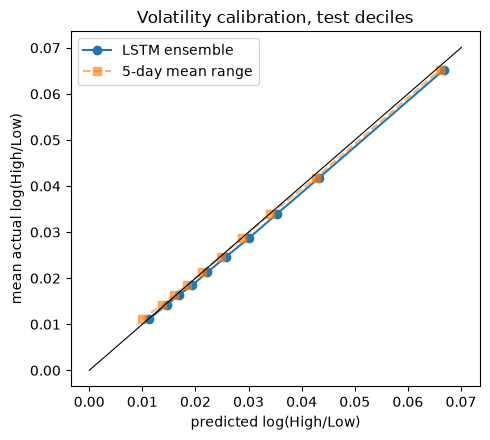

In [8]:
pr, pv = ens_pred[:, 0] * y_std, ens_pred[:, 1] * vol_std
cal = (
    pl.DataFrame({"pred": pv[test], "actual": y_vol[test], "ref": ref_vol[test]})
    .with_columns(bin=pl.col("pred").qcut(10, labels=[str(i) for i in range(10)]))
    .group_by("bin").agg(pred=pl.col("pred").mean(), actual=pl.col("actual").mean(), ref=pl.col("ref").mean())
    .sort("pred")
)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot(cal["pred"], cal["actual"], "o-", label="LSTM ensemble")
ax.plot(cal["ref"], cal["actual"], "s--", alpha=0.6, label="5-day mean range")
lim = [0, float(max(cal["pred"].max(), cal["actual"].max()) * 1.05)]
ax.plot(lim, lim, c="black", lw=0.8)
ax.set(xlabel="predicted log(High/Low)", ylabel="mean actual log(High/Low)", title="Volatility calibration, test deciles")
ax.legend()
fig.tight_layout()
plt.show()

## What the return head actually predicts

The return head has no demonstrated skill, so its predictions should be small and close to zero. Below, the spread of its
predictions on the test period against the spread of actual returns.

Standard deviation of predicted next-day log returns: **0.00172**, of actual returns: **0.02782** (ratio 0.062). Mean prediction +0.00045, mean actual -0.00004.

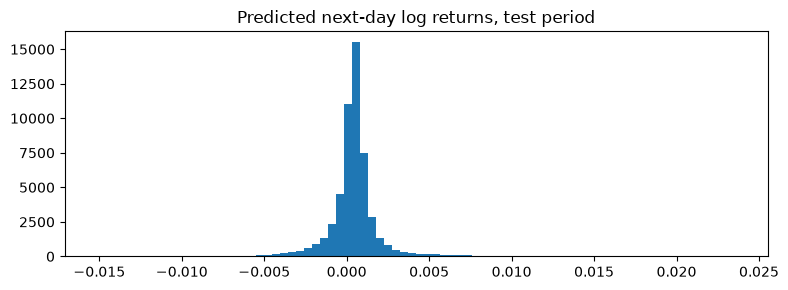

In [9]:
display(Markdown(
    f"Standard deviation of predicted next-day log returns: **{pr[test].std():.5f}**, of actual returns: **{y[test].std():.5f}** "
    f"(ratio {pr[test].std() / y[test].std():.3f}). Mean prediction {pr[test].mean():+.5f}, mean actual {y[test].mean():+.5f}."
))
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(np.clip(pr[test], -0.03, 0.03), bins=80)
ax.set(title="Predicted next-day log returns, test period")
fig.tight_layout()
plt.show()

## Per-ticker view and price forecast

In [10]:
per_ticker = (
    pl.DataFrame({"ticker": ticker[test], "y": y[test], "pr": pr[test], "v": y_vol[test], "pv": pv[test], "ref": ref_vol[test], "gb": gb_vol[test]})
    .group_by("ticker")
    .agg(
        n=pl.len(),
        ret_mse=((pl.col("y") - pl.col("pr")) ** 2).mean(), ret_zero=(pl.col("y") ** 2).mean(),
        vol_mse=((pl.col("v") - pl.col("pv")) ** 2).mean(), vol_ref=((pl.col("v") - pl.col("ref")) ** 2).mean(), vol_gb=((pl.col("v") - pl.col("gb")) ** 2).mean(),
    )
    .with_columns(
        ret_r2_vs_zero=1 - pl.col("ret_mse") / pl.col("ret_zero"),
        vol_r2_vs_ref=1 - pl.col("vol_mse") / pl.col("vol_ref"),
        vol_r2_vs_gb=1 - pl.col("vol_mse") / pl.col("vol_gb"),
    )
    .sort("vol_r2_vs_ref", descending=True)
)
k = per_ticker.height
display(Markdown(
    f"On the test period the ensemble beats zero return on **{per_ticker.filter(pl.col('ret_r2_vs_zero') > 0).height} of {k}** tickers, "
    f"the 5-day mean range on **{per_ticker.filter(pl.col('vol_r2_vs_ref') > 0).height} of {k}**, and gradient boosting on "
    f"**{per_ticker.filter(pl.col('vol_r2_vs_gb') > 0).height} of {k}**."
))
per_ticker.select("ticker", "n", r4("ret_r2_vs_zero"), r4("vol_r2_vs_ref"), r4("vol_r2_vs_gb"))

On the test period the ensemble beats zero return on **36 of 61** tickers, the 5-day mean range on **61 of 61**, and gradient boosting on **47 of 61**.

ticker,n,ret_r2_vs_zero,vol_r2_vs_ref,vol_r2_vs_gb
str,u32,f32,f64,f64
"""AAPL""",872,0.0023,0.241,0.0348
"""DIS""",872,-0.0037,0.2225,0.0171
"""FDX""",872,0.0083,0.2176,0.0226
"""DAL""",872,0.0007,0.2166,0.023
"""LUV""",872,-0.0009,0.205,0.0138
…,…,…,…,…
"""COIN""",872,-0.0004,0.0888,0.006
"""KO""",872,-0.0172,0.0884,0.0235
"""UL""",872,-0.0026,0.0844,0.0492


In [11]:
actual_close = close * np.exp(y)
mape = lambda pred, mask: float(np.mean(np.abs(pred[mask] - actual_close[mask]) / actual_close[mask]) * 100)
price = pl.DataFrame(
    {
        "model": ["tomorrow = today", "LSTM ensemble"],
        "val_MAPE_%": [mape(close, val), mape(close * np.exp(pr), val)],
        "test_MAPE_%": [mape(close, test), mape(close * np.exp(pr), test)],
    }
)
price.with_columns(pl.col("val_MAPE_%", "test_MAPE_%").round(4))

model,val_MAPE_%,test_MAPE_%
str,f64,f64
"""tomorrow = today""",1.6709,1.7845
"""LSTM ensemble""",1.6622,1.7856


## Summary and limitations

In [12]:
t = results.filter((pl.col("split") == "test") & (pl.col("model") == "LSTM ensemble")).row(0, named=True)
display(Markdown(f"""
**LSTM ensemble, test period (2022 onward)**

- **Return / next close price:** R² vs zero {t['ret_r2_vs_zero']:+.4f}, direction accuracy {t['ret_direction']:.3f}. The gain over predicting zero is
  {t['ret_gain']:.1e} ± {t['ret_ci95']:.1e}, so it is {'significant' if t['ret_gain'] - t['ret_ci95'] > 0 else 'not distinguishable from zero'}.
  The price forecast is effectively "tomorrow's close plus a small adjustment".
- **Volatility:** R² {t['vol_r2']:.3f}. It beats the 5-day mean range by {t['vol_r2_vs_ref']:+.3f} R² (gain {t['vol_gain_vs_ref']:.1e} ± {t['vol_ci_ref']:.1e}).
  Against gradient boosting the gain is {t['vol_gain_vs_gb']:.1e} ± {t['vol_ci_gb']:.1e}.

**Limitations**
- Daily returns are close to unpredictable. The price forecast should not be used as a trading signal.
- Volatility is a daily intraday range, not a standard deviation of returns.
- Trained on data to 2018 with validation to 2021, and not refit on later data.
- 8 of the 61 tickers have no training windows. Their forecasts use the shared model and are less reliable.
- The model assumes the cleaning and features in `stock_data.py`, and needs the market return of all tickers for the same days.
"""))


**LSTM ensemble, test period (2022 onward)**

- **Return / next close price:** R² vs zero +0.0019, direction accuracy 0.509. The gain over predicting zero is
  1.4e-06 ± 4.4e-06, so it is not distinguishable from zero.
  The price forecast is effectively "tomorrow's close plus a small adjustment".
- **Volatility:** R² 0.582. It beats the 5-day mean range by +0.153 R² (gain 3.4e-05 ± 1.0e-05).
  Against gradient boosting the gain is 3.5e-06 ± 3.0e-06.

**Limitations**
- Daily returns are close to unpredictable. The price forecast should not be used as a trading signal.
- Volatility is a daily intraday range, not a standard deviation of returns.
- Trained on data to 2018 with validation to 2021, and not refit on later data.
- 8 of the 61 tickers have no training windows. Their forecasts use the shared model and are less reliable.
- The model assumes the cleaning and features in `stock_data.py`, and needs the market return of all tickers for the same days.


## Save

In [13]:
OUT = Path("../models")
OUT.mkdir(exist_ok=True)
torch.save(
    {
        "name": "LSTM ensemble (3 seeds)",
        "states": [m.state_dict() for m in members],
        "config": {"hidden": 64, "use_ticker": False, "n_features": len(sd.FEATURES), "n_tickers": 0},
        "mean": mean.tolist(),
        "std": std.tolist(),
        "y_std": y_std,
        "vol_std": vol_std,
        "features": sd.FEATURES,
        "window": sd.WINDOW,
        "tickers": tickers.tolist(),
    },
    OUT / "lstm_two_head.pt",
)
metadata = {
    "model": "LSTM ensemble (3 seeds: 42, 43, 44), 64 hidden units, 2 layers, two heads",
    "targets": {"return": "next-day log return; price = Close * exp(return)", "volatility": "next-day log(High/Low)"},
    "window": sd.WINDOW,
    "features": sd.FEATURES,
    "train_tickers": int(len(train_tickers)),
    "split": {"val_start": str(sd.VAL_START), "test_start": str(sd.TEST_START)},
    "test_metrics": {k: v for k, v in t.items() if k not in ("model", "split")},
}
(OUT / "lstm_two_head.json").write_text(json.dumps(metadata, indent=2))
results.write_csv("../data/processed/final_results.csv")
print("saved", OUT / "lstm_two_head.pt")

saved ../models/lstm_two_head.pt
